In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [ ]:
from pathlib import Path
import pandas as pd

# Dataset location
DATASET_DIR = Path(r"D:\soilDatasets\dataset_v3")

# Image settings
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 64
NUM_CLASSES = 3

# Class mapping
CLASS_NAMES = {
    0: "Clay",
    1: "Loam",
    2: "Sand"
}

CLASS_TO_ID = {
    "Clay": 0,
    "Loam": 1,
    "Sand": 2
}

# Check dataset
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

# Create DataFrame directly from dataset folders
records = []

for split in ["train", "val", "test"]:
    split_dir = DATASET_DIR / split

    for class_name, class_id in CLASS_TO_ID.items():
        class_dir = split_dir / class_name

        for image_path in class_dir.glob("*.jpg"):
            records.append({
                "image_path": str(image_path.relative_to(DATASET_DIR)),
                "class_id": class_id,
                "class_name": class_name,
                "split": split
            })

df = pd.DataFrame(records)

# Create train / validation / test DataFrames
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("\nDataset loaded successfully.")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", CLASS_NAMES)

Dataset directory: D:\soilDatasets\dataset_v3
Dataset exists: True

Dataset loaded successfully.
Train: 70233
Validation: 10729
Test: 11088
Classes: {0: 'Clay', 1: 'Loam', 2: 'Sand'}


In [4]:
# Extract paths and labels
train_paths = train_df["image_path"].values
train_labels = train_df["class_id"].values

val_paths = val_df["image_path"].values
val_labels = val_df["class_id"].values

test_paths = test_df["image_path"].values
test_labels = test_df["class_id"].values

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

print("TensorFlow datasets created successfully.")
print("Train samples:", len(train_paths))
print("Validation samples:", len(val_paths))
print("Test samples:", len(test_paths))

TensorFlow datasets created successfully.
Train samples: 70233
Validation samples: 10729
Test samples: 11088


In [22]:
def load_image(image_path, label):
    # Convert relative path to full dataset path
    image_path = tf.strings.join([
        tf.constant(str(DATASET_DIR)),
        image_path
    ], separator="/")

    # Read image
    image = tf.io.read_file(image_path)

    # Decode JPG as RGB
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize to required size
    image = tf.image.resize(image, IMAGE_SIZE)

    # Convert image pixels to float32
    image = tf.cast(image, tf.float32)

    # Convert label to integer
    label = tf.cast(label, tf.int32)

    return image, label

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = (
    train_dataset
    .shuffle(2000)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Dataset pipelines created successfully.")

Dataset pipelines created successfully.


In [8]:
# Check whether all image files exist

from pathlib import Path

missing_train = []
missing_val = []
missing_test = []

for p in train_paths:
    full_path = Path(DATASET_DIR) / str(p)
    if not full_path.exists():
        missing_train.append(str(p))

for p in val_paths:
    full_path = Path(DATASET_DIR) / str(p)
    if not full_path.exists():
        missing_val.append(str(p))

for p in test_paths:
    full_path = Path(DATASET_DIR) / str(p)
    if not full_path.exists():
        missing_test.append(str(p))

print("Missing train images:", len(missing_train))
print("Missing validation images:", len(missing_val))
print("Missing test images:", len(missing_test))

if missing_train:
    print("\nExample missing train file:")
    print(missing_train[0])

if missing_val:
    print("\nExample missing validation file:")
    print(missing_val[0])

if missing_test:
    print("\nExample missing test file:")
    print(missing_test[0])

Missing train images: 0
Missing validation images: 0
Missing test images: 0


In [9]:
import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nDATASET_DIR:")
print(DATASET_DIR)

print("\nFirst training path:")
print(repr(train_paths[0]))

# Build the path exactly like TensorFlow does
tf_full_path = tf.strings.join([
    tf.constant(str(DATASET_DIR)),
    tf.constant(str(train_paths[0]))
], separator="/")

print("\nTensorFlow path:")
print(tf_full_path.numpy().decode())

print("\nDoes TensorFlow see the file?")
print(tf.io.gfile.exists(tf_full_path.numpy().decode()))

print("\nDoes Python see the file?")
python_path = Path(str(DATASET_DIR)) / str(train_paths[0])
print(python_path)
print(python_path.exists())

Current working directory:
d:\J26-IT-433-Soil-Assessment\J26-IT-433-Soil-Assessment-Planner\component1\notebooks

DATASET_DIR:
D:\soilDatasets\dataset_v3

First training path:
'train\\Clay\\123b85296021_0000.jpg'

TensorFlow path:
D:\soilDatasets\dataset_v3/train\Clay\123b85296021_0000.jpg

Does TensorFlow see the file?
True

Does Python see the file?
D:\soilDatasets\dataset_v3\train\Clay\123b85296021_0000.jpg
True


In [10]:
from pathlib import Path

filename = "123b85296021_0000.jpg"

print("Searching for:", filename)
print()

matches = list(Path(DATASET_DIR).parent.parent.rglob(filename))

print("Matches found:", len(matches))

for p in matches[:20]:
    print(p)

Searching for: 123b85296021_0000.jpg

Matches found: 1
D:\SoilDatasets\dataset_v3\train\Clay\123b85296021_0000.jpg


In [11]:
from pathlib import Path

filename = "123b85296021_0000.jpg"

print("Searching for:", filename)
print()

matches = list(Path(DATASET_DIR).parent.parent.rglob(filename))

print("Matches found:", len(matches))

for p in matches[:20]:
    print(p)

Searching for: 123b85296021_0000.jpg

Matches found: 1
D:\SoilDatasets\dataset_v3\train\Clay\123b85296021_0000.jpg


In [12]:
# Test one real image directly

from pathlib import Path
import tensorflow as tf

test_image = Path(DATASET_DIR) / "train" / "Clay" / "123b85296021_0000.jpg"

print("Testing image:")
print(test_image)

print("\nPython sees file:", test_image.exists())

if test_image.exists():
    image_bytes = tf.io.read_file(str(test_image))
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    print("Image loaded successfully!")
    print("Shape:", image.shape)
    print("Dtype:", image.dtype)
    print("Min:", tf.reduce_min(image).numpy())
    print("Max:", tf.reduce_max(image).numpy())
else:
    print("ERROR: Image not found!")

Testing image:
D:\soilDatasets\dataset_v3\train\Clay\123b85296021_0000.jpg

Python sees file: True
Image loaded successfully!
Shape: (224, 224, 3)
Dtype: <dtype: 'float32'>
Min: 0.0
Max: 1.0


In [23]:
# Recreate raw TensorFlow datasets from image paths and labels

train_dataset_raw = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_dataset_raw = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_dataset_raw = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

print("Raw datasets recreated successfully.")
print("Train samples:", len(train_paths))
print("Validation samples:", len(val_paths))
print("Test samples:", len(test_paths))

Raw datasets recreated successfully.
Train samples: 70233
Validation samples: 10729
Test samples: 11088


In [24]:
# Create final image loading and preprocessing pipelines

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = (
    train_dataset_raw
    .shuffle(2000)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset_raw
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset_raw
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Final dataset pipelines created successfully.")

Final dataset pipelines created successfully.


In [25]:
# Verify one training batch

images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Image data type:", images.dtype)
print("Label batch shape:", labels.shape)
print("Label data type:", labels.dtype)
print("Pixel minimum:", tf.reduce_min(images).numpy())
print("Pixel maximum:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Image data type: <dtype: 'float32'>
Label batch shape: (32,)
Label data type: <dtype: 'int32'>
Pixel minimum: 0.0
Pixel maximum: 255.0


In [26]:
# Build EfficientNetB0 model

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Load EfficientNetB0 without the original ImageNet classifier
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained base model initially
base_model.trainable = False

# Build classification model
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Display model structure
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [27]:
# Compile the model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [29]:
# Train EfficientNetB0

EPOCHS = 2

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/2
2195/2195 ━━━━━━━━━━━━━━━━━━━━ 3339s 2s/step - accuracy: 0.9886 - loss: 0.0415 - val_accuracy: 0.4855 - val_loss: 2.1156
Epoch 2/2
2195/2195 ━━━━━━━━━━━━━━━━━━━━ 2347s 1s/step - accuracy: 0.9881 - loss: 0.0405 - val_accuracy: 0.5823 - val_loss: 1.7416


In [20]:
# Check EfficientNetB0 configuration

print("Model variable available:", "model" in globals())

print("\nTensorFlow version:", tf.__version__)

print("\nEfficientNetB0 preprocessing:")
print("Input size:", IMAGE_SIZE)
print("Input range from our pipeline: 0.0 to 1.0")

print("\nDataset sample:")
images, labels = next(iter(val_dataset))

print("Image shape:", images.shape)
print("Image dtype:", images.dtype)
print("Image min:", tf.reduce_min(images).numpy())
print("Image max:", tf.reduce_max(images).numpy())

print("\nValidation labels in this batch:")
print(labels.numpy())

print("\nLabel counts in this batch:")
print(np.bincount(labels.numpy(), minlength=NUM_CLASSES))

Model variable available: False

TensorFlow version: 2.21.0

EfficientNetB0 preprocessing:
Input size: (224, 224)
Input range from our pipeline: 0.0 to 1.0

Dataset sample:
Image shape: (32, 224, 224, 3)
Image dtype: <dtype: 'float32'>
Image min: 0.0
Image max: 1.0

Validation labels in this batch:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Label counts in this batch:
[32  0  0]


In [24]:
# Check class distribution in train, validation and test sets

print("TRAIN CLASS DISTRIBUTION")
print(train_df["class_id"].value_counts().sort_index())

print("\nVALIDATION CLASS DISTRIBUTION")
print(val_df["class_id"].value_counts().sort_index())

print("\nTEST CLASS DISTRIBUTION")
print(test_df["class_id"].value_counts().sort_index())

print("\nClass names:")
print(CLASS_NAMES)

TRAIN CLASS DISTRIBUTION
class_id
0    24623
1    29082
2    16528
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION
class_id
0    2012
1    6317
2    2400
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
class_id
0    2352
1    6336
2    2400
Name: count, dtype: int64

Class names:
{0: 'Clay', 1: 'Loam', 2: 'Sand'}


In [25]:
# Check what classes the model predicts on the validation set

import numpy as np

y_true = []
y_pred = []

for images, labels in val_dataset:
    predictions = model.predict(images, verbose=0)
    
    predicted_classes = np.argmax(predictions, axis=1)
    
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual validation class counts:")
print(np.bincount(y_true, minlength=NUM_CLASSES))

print("\nPredicted validation class counts:")
print(np.bincount(y_pred, minlength=NUM_CLASSES))

print("\nClass names:")
for i, name in CLASS_NAMES.items():
    print(i, "=", name)

Actual validation class counts:
[2012 6317 2400]

Predicted validation class counts:
[    0     0 10729]

Class names:
0 = Clay
1 = Loam
2 = Sand


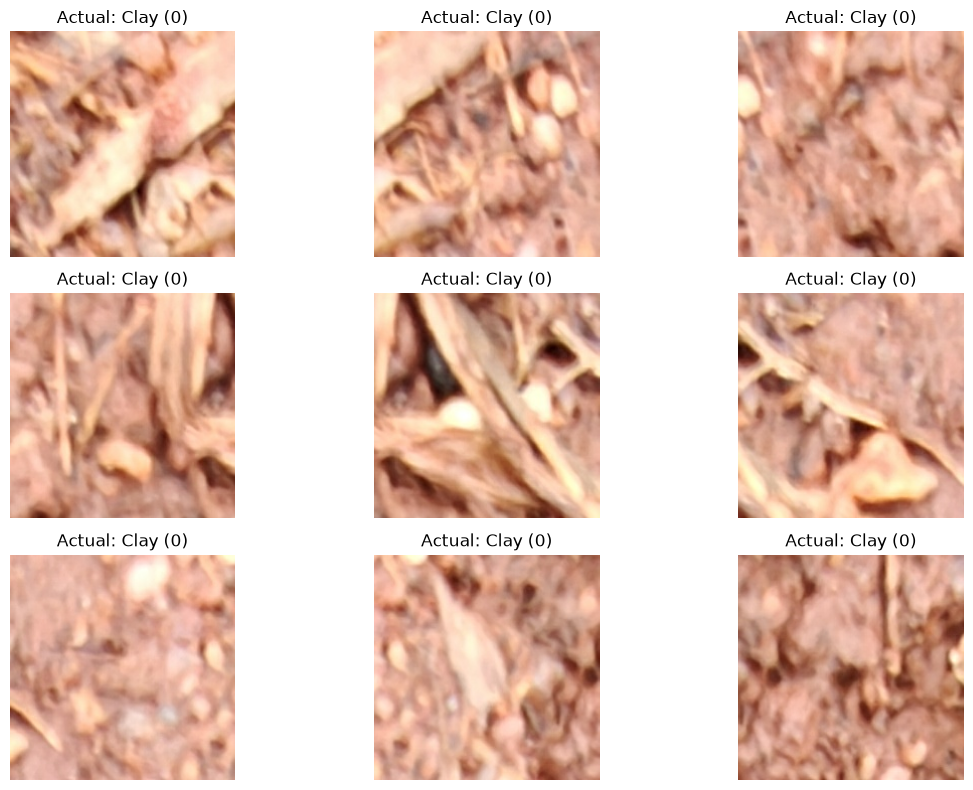

In [17]:
# Check a few validation images and their actual labels

import matplotlib.pyplot as plt
import numpy as np

# Take one batch from validation dataset
images, labels = next(iter(val_dataset))

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())

    label_id = int(labels[i].numpy())
    label_name = CLASS_NAMES[label_id]

    plt.title(f"Actual: {label_name} ({label_id})")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Test model predictions on only the first validation batch

predictions = model.predict(images, verbose=0)

predicted_classes = np.argmax(predictions, axis=1)

print("Actual labels:")
print(labels.numpy())

print("\nPredicted labels:")
print(predicted_classes)

print("\nPredicted class counts:")
print(np.bincount(predicted_classes, minlength=NUM_CLASSES))

print("\nClass names:")
for i, name in CLASS_NAMES.items():
    print(i, "=", name)

NameError: name 'model' is not defined

In [19]:
from pathlib import Path

print("Is model variable available?", "model" in globals())

print("\nModel files found:")

for path in Path("../models").rglob("*"):
    if path.is_file():
        print(path)

Is model variable available? False

Model files found:
